# 155. Min Stack
**Difficulty:** 🟡 Medium · **Topic:** Stack · **Pattern:** [Stack Simulation](README.md) · **LeetCode:** https://leetcode.com/problems/min-stack/

## 💡 Concepts

**Core concept(s):** a **stack** whose every entry also remembers the **minimum of everything at or below it**.

**Why it applies here:**
- A stack only ever changes at the top. So the set of values *below* any entry never changes while that entry is on the stack.
- That means "the minimum of the stack, as it was when this entry was pushed" is a fact that stays true until the entry is popped.
- Store that fact next to the value, and `getMin` becomes a lookup on the top entry instead of a scan.

**Key intuition:**
- Each push writes `(val, min(val, min below))` on top.
- A pop removes the top pair, and the pair underneath already holds the correct minimum for the smaller stack. Nothing has to be recomputed.

---

### 📚 What is a Stack?
- A **stack** is a "last in, first out" pile, like a stack of plates.
- You **push** onto the top, **pop** from the top, and **peek** at the top. You never touch the middle.
- **Complexity:** push / pop / peek are **O(1)**.
- **In Python:** a plain `list`: `append(x)` pushes, `pop()` removes the top, `lst[-1]` peeks.

### 📚 What is a "design" problem?
- Instead of one function, you implement a **class**. LeetCode then calls its methods in a given order.
- The input is two parallel lists: method names (`["MinStack", "push", "getMin", ...]`) and their arguments (`[[], [-2], [], ...]`).
- The expected output lists each call's return value (`null` / `None` for methods that return nothing).
- The tests below replay those lists with a small `run_ops` helper.

### 📚 What is a running minimum?
- A **running minimum** is the smallest value seen so far as you walk a sequence: `m_i = min(m_{i-1}, x_i)`.
- Updating it costs **O(1)** per new value.
- The catch: it can only move forward. When a value *leaves* (a pop), a single number cannot tell you the previous minimum. Keeping one running minimum **per stack entry** fixes that.

---

**Prerequisite knowledge:**
- Python classes (`__init__`, methods, `self`).
- Tuples, and indexing a tuple (`pair[0]`, `pair[1]`).

## 📝 Problem

Design a stack that supports, each in **O(1)** time:
- `push(val)` — put `val` on top.
- `pop()` — remove the top element.
- `top()` — return the top element.
- `getMin()` — return the smallest element currently in the stack.

**Example**
```
ops  = ["MinStack", "push", "push", "push", "getMin", "pop", "top", "getMin"]
args = [[],         [-2],   [0],    [-3],   [],       [],    [],    []]
out  = [None,       None,   None,   None,   -3,       None,  0,     -2]
```
After popping `-3`, the minimum must go **back** to `-2`. That is the whole difficulty.

**Constraints:** `-2^31 <= val <= 2^31 - 1`; `pop`, `top` and `getMin` are only called on a non-empty stack; at most `3 * 10^4` calls.

> Two approaches: a plain stack that scans for the minimum (`O(n)` per `getMin`), then the pattern's answer, `(value, min so far)` pairs (`O(1)` per call).

In [1]:
from typing import List, Optional

def run_ops(cls, ops: List[str], args: List[list]) -> List[Optional[int]]:
    """Replay a LeetCode design-problem script: ops[0] is the constructor, the rest are method calls.
    Returns one output per call (None for methods that return nothing), like LeetCode's expected output."""
    obj, out = cls(), [None]               # the constructor call outputs null
    for op, a in zip(ops[1:], args[1:]):
        out.append(getattr(obj, op)(*a))   # e.g. obj.push(-2), obj.getMin()
    return out

### Approach 1 — Brute Force: a plain stack, scan on `getMin`

**Idea:**
1. Keep the values in a plain list used as a stack.
2. `push`, `pop` and `top` are the usual list operations.
3. `getMin` calls `min(self.stack)`, which walks every element.

**Time complexity:** `O(1)` for `push` / `pop` / `top`, but `O(n)` for `getMin` (`n` = current stack size). A script of `n` pushes followed by `n` `getMin` calls costs `O(n²)`.

**Space complexity:** `O(n)` for the values.

In [2]:
class MinStackScan:
    def __init__(self):
        self.stack = []                    # just the values, bottom -> top

    def push(self, val: int) -> None:
        self.stack.append(val)

    def pop(self) -> None:
        self.stack.pop()

    def top(self) -> int:
        return self.stack[-1]

    def getMin(self) -> int:
        return min(self.stack)             # O(n): walks every element on each call

### Approach 2 — Stack of `(value, min so far)` pairs (optimal · pattern template)

**Idea:** the [Stack Simulation](README.md) template, where each pushed item carries the state needed to answer queries.
1. On `push(val)`: the new minimum is `min(val, minimum stored on the current top)` (or `val` if the stack is empty). Push the pair `(val, new_min)`.
2. On `pop()`: pop the pair. The pair now on top already stores the minimum of the smaller stack, so the old minimum is "restored" for free.
3. `top()` reads `self.stack[-1][0]`; `getMin()` reads `self.stack[-1][1]`.

**Time complexity:** `O(1)` for every operation, so `O(n)` for a script of `n` calls.

**Space complexity:** `O(n)` — two numbers per element instead of one.

> Variant with the same complexity: **two stacks**, one for values and one for minimums (push to the min-stack only when `val <= current min`, pop from it when the popped value equals the current min). The pairs version has no `<=` vs `<` edge case to get wrong, so it is the one used here.

In [3]:
class MinStack:
    def __init__(self):
        self.stack = []                    # (val, min of this entry and everything below it)

    def push(self, val: int) -> None:
        cur_min = min(val, self.stack[-1][1]) if self.stack else val
        self.stack.append((val, cur_min))  # the min "as of this height" travels with the value

    def pop(self) -> None:
        self.stack.pop()                   # the pair below already holds the older min

    def top(self) -> int:
        return self.stack[-1][0]

    def getMin(self) -> int:
        return self.stack[-1][1]           # O(1): no scan

In [4]:
# Correctness check
import random

tests = [
    (["MinStack", "push", "push", "push", "getMin", "pop", "top", "getMin"],      # LeetCode example
     [[], [-2], [0], [-3], [], [], [], []],
     [None, None, None, None, -3, None, 0, -2]),
    (["MinStack", "push", "push", "push", "getMin", "pop", "getMin"],             # duplicate minimum
     [[], [0], [1], [0], [], [], []],
     [None, None, None, None, 0, None, 0]),
    (["MinStack", "push", "push", "push", "getMin", "pop", "getMin", "pop", "getMin"],  # min only at the bottom
     [[], [1], [2], [3], [], [], [], [], []],
     [None, None, None, None, 1, None, 1, None, 1]),
    (["MinStack", "push", "getMin", "top", "pop", "push", "getMin"],              # stack emptied, then reused
     [[], [5], [], [], [], [7], []],
     [None, None, 5, 5, None, None, 7]),
    (["MinStack", "push", "push", "getMin", "pop", "getMin"],                     # 32-bit extremes
     [[], [2**31 - 1], [-2**31], [], [], []],
     [None, None, None, -2**31, None, 2**31 - 1]),
]
for ops, args, exp in tests:
    a, b = run_ops(MinStackScan, ops, args), run_ops(MinStack, ops, args)
    print(f"{str(ops[1:]):70} -> {b[1:]}")
    assert a == b == exp, f"mismatch: scan={a} pairs={b} expected={exp}"

# Randomised cross-check: both designs must answer every call identically
rng = random.Random(155)
for _ in range(300):
    ops, args, size = ["MinStack"], [[]], 0
    for _ in range(rng.randint(1, 60)):
        op = "push" if size == 0 else rng.choice(["push", "push", "pop", "top", "getMin"])
        ops.append(op)
        args.append([rng.randint(-20, 20)] if op == "push" else [])
        size += {"push": 1, "pop": -1}.get(op, 0)
    assert run_ops(MinStackScan, ops, args) == run_ops(MinStack, ops, args), (ops, args)
print("300 random scripts: both designs agree")

print("\nAll tests passed")

['push', 'push', 'push', 'getMin', 'pop', 'top', 'getMin']             -> [None, None, None, -3, None, 0, -2]
['push', 'push', 'push', 'getMin', 'pop', 'getMin']                    -> [None, None, None, 0, None, 0]
['push', 'push', 'push', 'getMin', 'pop', 'getMin', 'pop', 'getMin']   -> [None, None, None, 1, None, 1, None, 1]
['push', 'getMin', 'top', 'pop', 'push', 'getMin']                     -> [None, 5, 5, None, None, 7]
['push', 'push', 'getMin', 'pop', 'getMin']                            -> [None, None, -2147483648, None, 2147483647]
300 random scripts: both designs agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | ≈ **2×** (slightly more) |
| `O(n²)`       | ≈ **4×** |

Here `n` is the number of operations in the script. The worst case for the scan is a script of `n/2` pushes followed by `n/2` `getMin` calls: every `getMin` walks a full stack of `n/2` values, `n²/4` steps in total, so it should show ≈4×. The pairs design does `O(1)` work per call and should show ≈2×.


scan getMin, O(n^2) total
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       5.86 |           n/a
     4000 |      21.81 |         3.72x
     8000 |      84.86 |         3.89x


    16000 |     346.85 |         4.09x

(val, min) pairs, O(n) total
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       0.31 |           n/a
     4000 |       0.60 |         1.95x
     8000 |       1.19 |         1.97x
    16000 |       2.71 |         2.28x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


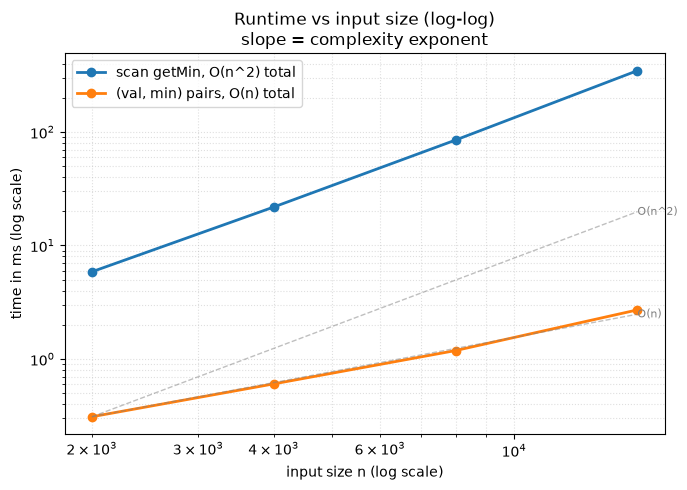

{'scan getMin, O(n^2) total': [5.864792037755251,
  21.813583094626665,
  84.86016700044274,
  346.85283398721367],
 '(val, min) pairs, O(n) total': [0.30987500213086605,
  0.6033750250935555,
  1.1864160187542439,
  2.7065000031143427]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    half = n // 2
    ops = ["MinStack"] + ["push"] * half + ["getMin"] * half
    args = [[]] + [[v] for v in range(half)] + [[]] * half
    return (ops, args)

solutions = {
    "scan getMin, O(n^2) total": lambda ops, args: run_ops(MinStackScan, ops, args),
    "(val, min) pairs, O(n) total": lambda ops, args: run_ops(MinStack, ops, args),
}
sizes = [2000, 4000, 8000, 16000]

benchmark(solutions, make_worst_case, sizes, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Stack Simulation](README.md) — each push stores `(val, min so far)`, so the item on top always carries the answer to `getMin`, and a pop restores the previous answer automatically.
- **Augmented stack:** when a query must be answered for "the stack as it is now", store the query's answer *with each entry*. It works because a stack never changes below its top. The same trick gives a max-stack, or a running sum.
- **Signal:** "design a stack that also supports X in O(1)", "retrieve the minimum element in constant time", a design problem whose state must roll back on undo.
- **Related problems:** Max Stack, Implement Queue using Stacks, Sliding Window Maximum (a monotonic deque keeps the max of a window), Online Stock Span.
- **Common pitfalls:**
  1. Keeping one `self.min` variable: after the minimum is popped there is no way to know the previous one.
  2. In the two-stacks variant, pushing to the min-stack only on `val < min` (strict): with duplicates, popping one copy of the minimum wrongly removes it.
  3. Forgetting the empty-stack case in `push` (`self.stack[-1]` on an empty list raises `IndexError`).